# Stage 1, rehearsed on the virtual NEOARM

The same code as the real session: `acquire` drives the microscope through PyJEM, `analyse` turns
the frames into a model that predicts where the beam lands for any lens setting and any beam shift
or tilt, and `figures` shows the results.

Everything runs at **60 kV**. The virtual NEOARM is aligned at 60 kV by scaling its 200 kV lens
tables by p(60 kV)/p(200 kV) = 0.515, which gives the same optics. It differs from the real NEOARM
in three ways: its lens values are not the NEOARM's, its lenses settle instantly (`settle_s=0`
here, about 2 s for real), and its camera image is mirrored, which the analysis has to find by
itself.

## 1. The microscope

At the console: 60 kV, MAG at the 40k row, spot size, condenser aperture, camera binning and
exposure, specimen out. The virtual microscope is built in that state.

In [1]:
import os
os.environ["JAX_PLATFORMS"] = "cpu"

import acquire
import analyse
import figures
import virtual_neoarm

microscope = virtual_neoarm.build(ht_v=60e3)
TEM3, detector = microscope.pyjem()          # at the microscope: from PyJEM import TEM3, detector

## 2. Stage 1

One call. It reads the diffraction setting in DIFF at 40 cm (where the gold rings will fit on the
camera at 60 kV, for stage 2) and comes back to MAG. Then 12 visits: the 8 lens settings, the
diffraction setting, setting 0 twice more (to see how much the beam wobbles) and once with y kicks.
At each, a ± shift and a ± tilt of about 50 px.

DIFF at 40cm


first frame: 256x256, read as <i4, values -8 to 16 (if these look wrong, pass dtype='<u2' or similar)


visit 1/12 (setting 0, x kicks) done


visit 2/12 (setting 1, x kicks) done


visit 3/12 (setting 2, x kicks) done


visit 4/12 (setting 3, x kicks) done


... (4 outputs left out)

visit 9/12 (setting 7, x kicks) done


visit 10/12 (setting diffraction, x kicks) done


visit 11/12 (setting 0, x kicks) done


visit 12/12 (setting 0, y kicks) done


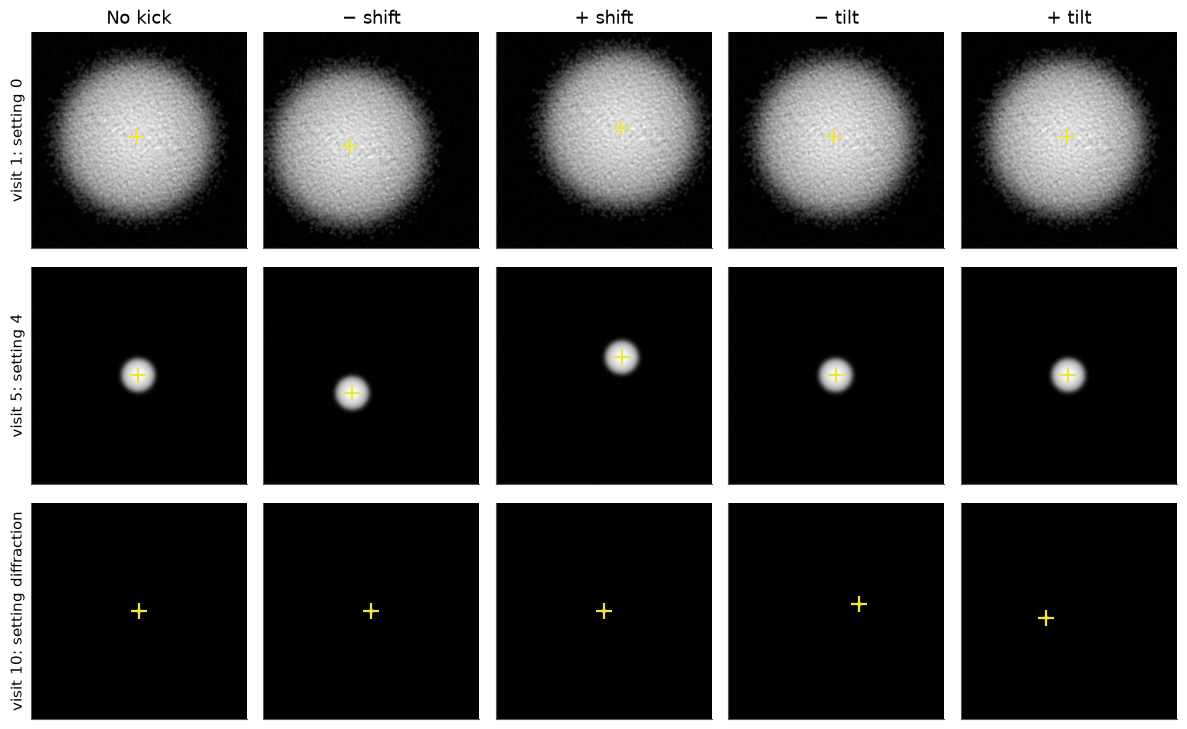

In [2]:
folder = acquire.stage1(TEM3, detector, "../generated/stage1_rehearsal/stage1", camera_length_cm=40, settle_s=0)
figures.frames(folder)

## 3. The model

The fit tries both camera handednesses and pure or mixed deflectors, and keeps the simplest that
fits to the wobble. χ²/dof near 1 means it does; far above 1, the worst-fitting measurements say
which visits to look at.

In [3]:
model = analyse.stage1(folder)
model

| stage-1 model | |
|---|---|
| camera image mirrored | True |
| deflector y axis flipped | False |
| deflectors | pure |
| beam-position wobble (from the repeats) | 0.005 px |
| χ²/dof (≈ 1: fits to the wobble) | 0.59 |
| worst-fitting measurements | visit 6 (0) shift: 0.010 px; visit 11 (0) shift: 0.005 px; visit 10 (diffraction) tilt: 0.005 px |

**What the model knows**, unscaled: at each lens setting, where the beam goes on the camera for
1000 units of CLA1 (shift) and of CLA2 (tilt). No metres, no radians: px and deflector units, as
measured. Shift does nothing at the diffraction setting; tilt does almost nothing where the
image is in focus (settings 0, 3, 4).

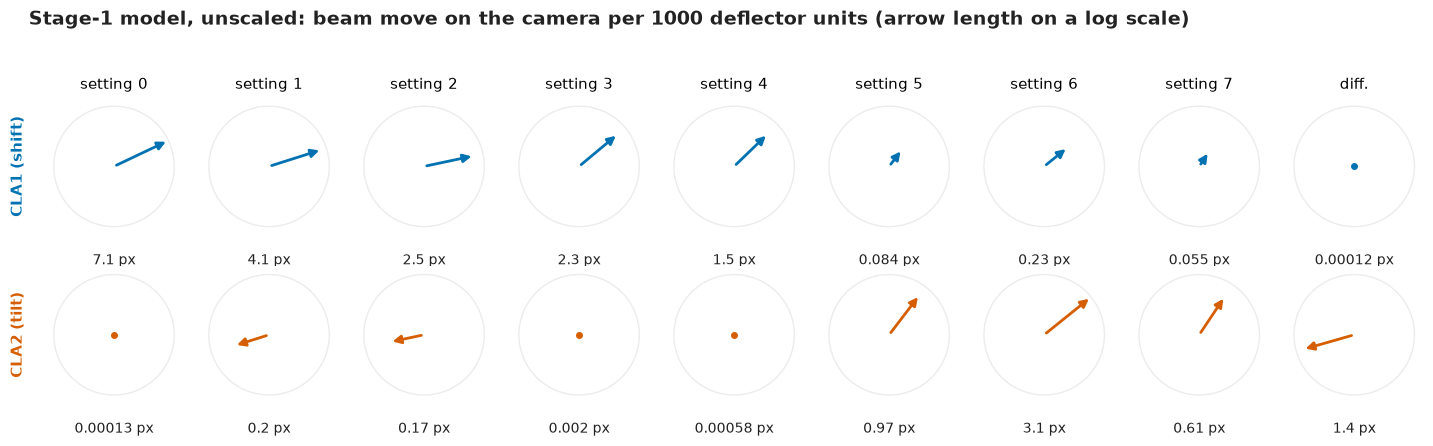

In [4]:
figures.model_response(model, folder)

**Why there is no single column yet.** Inside, the model is a TemGym column, which needs metres.
Stage 1 does not know the metres per shift unit or the radians per tilt unit, so the fit assumes
them, and other assumptions give other columns with exactly the same predictions. Here are four,
all at the 40k row. None is the physical microscope; stage 2 picks that one.

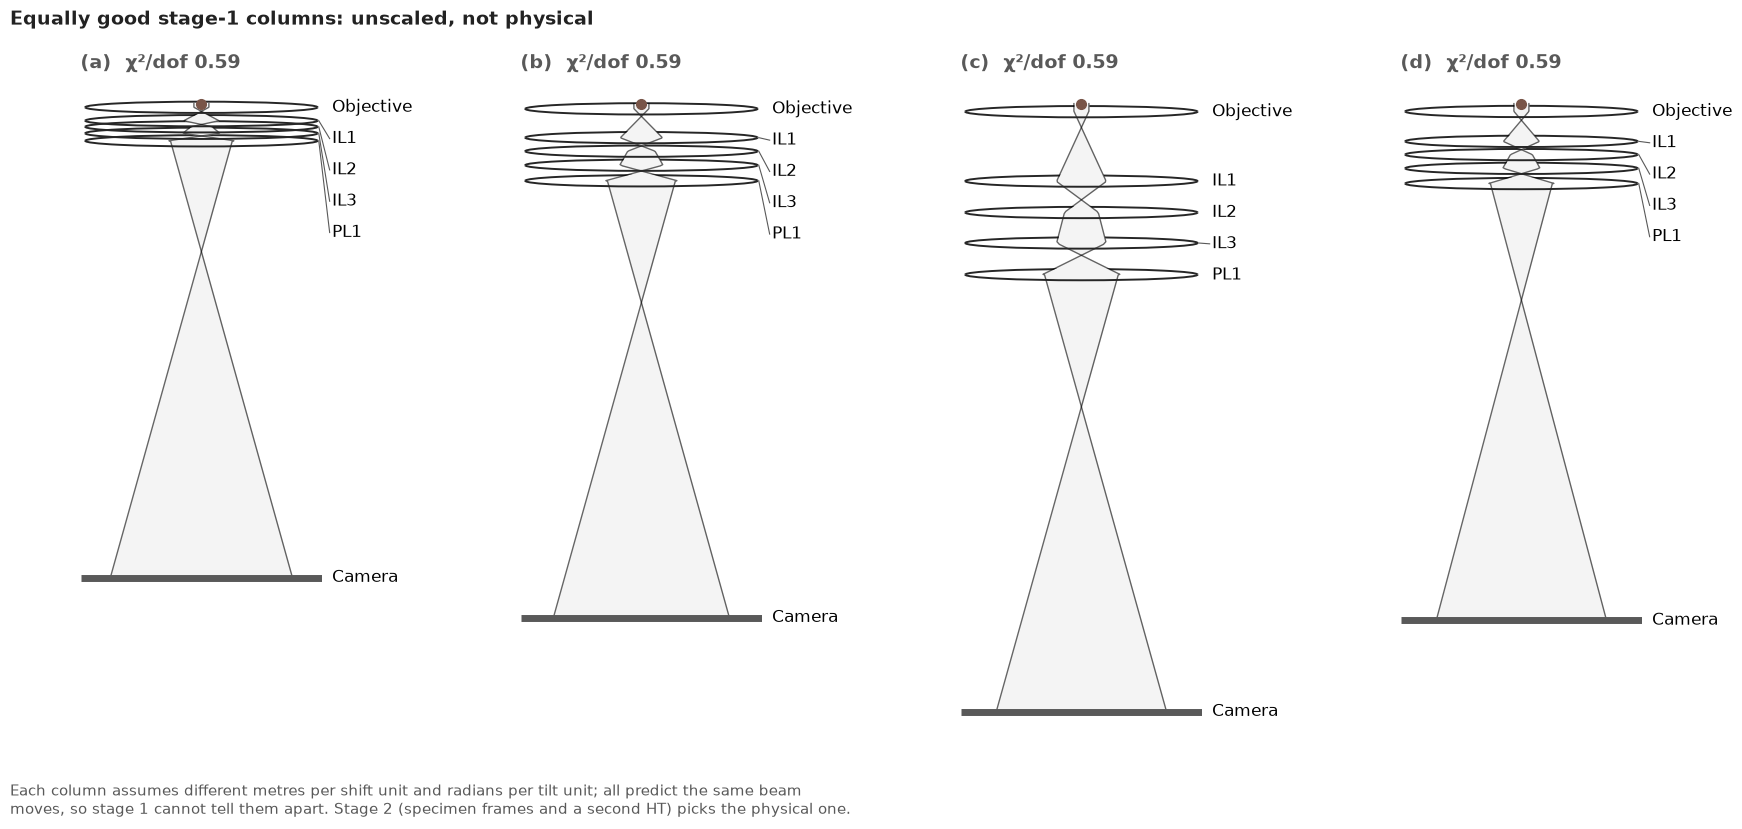

In [5]:
figures.model_family(model, analyse.equivalent_columns(folder, model))

## 4. Does it predict lens settings it never saw?

Eight new settings, each a blend of three measured ones. The model predicts each beam move
before it is measured.

first frame: 256x256, read as <i4, values -7 to 16 (if these look wrong, pass dtype='<u2' or similar)


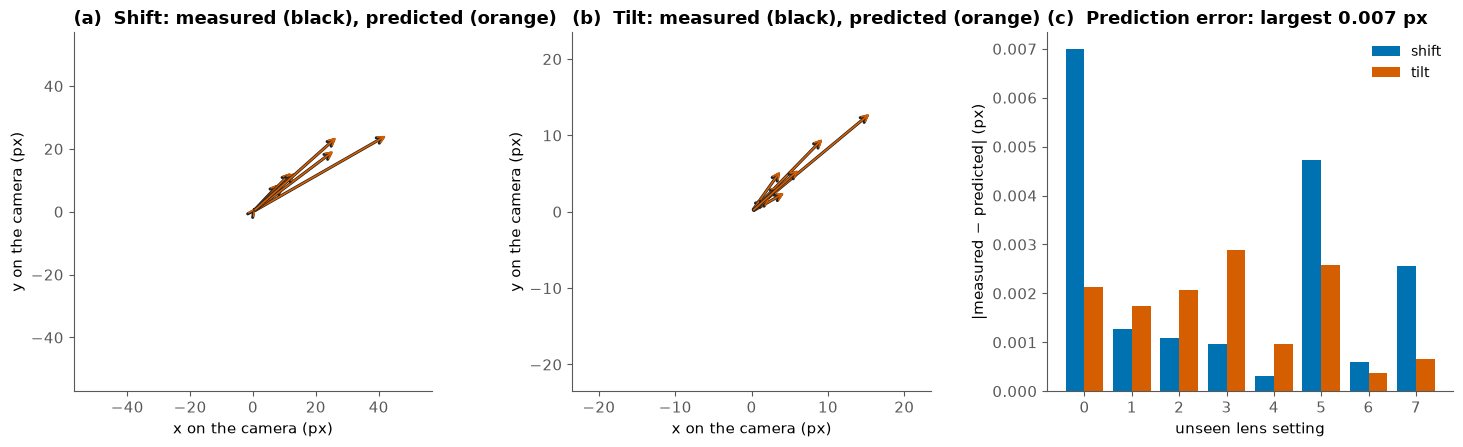

In [6]:
check = acquire.check(TEM3, detector, "../generated/stage1_rehearsal/check", analyse.unseen_settings(folder),
                      offsets=(10000, 10000), settle_s=0)
figures.prediction_check(analyse.compare(model, check))

## Bring back from the real session

The stage-1 folder, and a check folder if there was time. Then `analyse.stage1(folder)` and
`analyse.compare(model, check)`.